# Exploratory data analysis: what the data holds

Before building any forecast, this notebook looks at the synthetic actuals of our fictional EHS / ESG software company (Jan 2022 to Sep 2026).

Questions:
1. What tables do we have, and what does each column mean?
2. How big is the company and how fast does it grow?
3. How do the drivers behave: new customers, churn, price, discounts, partner sales?
4. What happened in 2026 that the budget did not expect?
5. What does this mean for the forecast?

All data is synthetic, created by `src/make_data.py`. It does not describe any real company.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

COLORS = {"Mid-market": "#2a6fdb", "Enterprise": "#e07b39"}

## 1. The two tables

| File | What it is | Rows |
|---|---|---|
| `data/actual_drivers.csv` | The **inputs**: one row per month and segment with the business drivers | 57 months x 2 segments |
| `outputs/actual_pnl.csv` | The **P&L**: the same rows plus customers, revenue lines, costs and margin, calculated from the drivers by `src/revenue_model.py` | same rows, more columns |

The drivers are what the business controls or observes (how many customers we won, how many left, what discount we gave). The P&L is the result. Budget, outlook and plan will use the same drivers, so understanding them is the first step.

In [2]:
drivers = pd.read_csv("../data/actual_drivers.csv", parse_dates=["month"])
pnl = pd.read_csv("../outputs/actual_pnl.csv", parse_dates=["month"])

print("drivers:", drivers.shape)
print("pnl:    ", pnl.shape)
print("months: ", drivers["month"].min().date(), "to", drivers["month"].max().date())
print("segments:", drivers["segment"].unique())

drivers: (114, 14)
pnl:     (114, 36)
months:  2022-01-01 to 2026-09-01
segments: <StringArray>
['Mid-market', 'Enterprise']
Length: 2, dtype: str


In [3]:
drivers.head()

,month,segment,new_customers,churn_rate,price_increase,expansion_rate,discount_rate,partner_share,commission_rate,onboarding_fee,hosting_cost_per_cust,support_cost_per_cust,services_cost_pct,licence_cost_pct
0,2022-01-01,Mid-market,9,0.012,0.000,0.002,0.082,0.293,0.200,6000,118.843,95.000,0.712,0.030
1,2022-02-01,Mid-market,5,0.009,0.000,0.000,0.083,0.273,0.200,6000,119.581,95.000,0.692,0.030
2,2022-03-01,Mid-market,8,0.009,0.000,0.002,0.075,0.302,0.200,6000,117.054,95.000,0.686,0.030
3,2022-04-01,Mid-market,11,0.005,0.000,0.002,0.077,0.309,0.200,6000,117.003,95.000,0.694,0.030
4,2022-05-01,Mid-market,5,0.011,0.000,0.002,0.082,0.283,0.200,6000,122.939,95.000,0.694,0.030


### What each driver means

| Column | Meaning | Unit |
|---|---|---|
| `new_customers` | Customers won in the month | count |
| `churn_rate` | Share of opening customers who cancelled in the month | % per month |
| `price_increase` | List price increase, only in January | % |
| `expansion_rate` | Monthly growth of the fee per customer from upsell (more modules or users) | % per month |
| `discount_rate` | Average discount and coupons on the list fee | % of list fee |
| `partner_share` | Share of subscription revenue sold through reseller partners | % |
| `commission_rate` | Commission paid to partners on that revenue | % |
| `onboarding_fee` | One-off implementation fee per new customer | EUR |
| `hosting_cost_per_cust`, `support_cost_per_cust` | Monthly cost to serve one customer | EUR |
| `services_cost_pct` | Delivery cost as a share of onboarding revenue | % |
| `licence_cost_pct` | Third-party licences as a share of gross subscription | % |

In [4]:
# Data quality: missing values and duplicates
print("missing values:", drivers.isna().sum().sum(), "/", pnl.isna().sum().sum())
print("duplicate month-segment rows:", drivers.duplicated(["month", "segment"]).sum())

missing values: 0 / 0
duplicate month-segment rows: 0


In [5]:
# Summary of the drivers by segment
drivers.groupby("segment")[["new_customers", "churn_rate", "expansion_rate", "discount_rate",
                            "partner_share", "commission_rate", "onboarding_fee"]].mean().T

segment,Enterprise,Mid-market
new_customers,1.825,10.000
churn_rate,0.005,0.010
expansion_rate,0.004,0.002
discount_rate,0.149,0.083
partner_share,0.100,0.308
commission_rate,0.150,0.200
onboarding_fee,"40,000.000","6,000.000"


### The P&L columns

The P&L follows one chain of formulas:

```
closing customers   = opening customers + new customers - churned customers
fee per customer    = last month's fee x (1 + price increase) x (1 + expansion)
gross subscription  = closing customers x fee per customer
net subscription    = gross subscription - discounts - partner commission
services revenue    = new customers x onboarding fee
net revenue         = net subscription + services revenue
gross profit        = net revenue - hosting - support - services delivery - licences
ARR                 = net subscription x 12
```

A quick check that the customer numbers add up:

In [6]:
check = pnl["opening_customers"] + pnl["new_customers"] - pnl["churned_customers"] - pnl["closing_customers"]
print("largest difference in the customer roll-forward:", check.abs().max())

largest difference in the customer roll-forward: 0.0


## 2. Size and growth

2026 has only nine months of actuals (Jan to Sep), so the 2026 row is not a full year.

In [7]:
yearly = pnl.groupby("year").agg(
    months=("month", "nunique"),
    net_revenue=("net_revenue", "sum"),
    gross_profit=("gross_profit", "sum"),
    new_customers=("new_customers", "sum"),
    churned=("churned_customers", "sum"),
)
yearly["gross_margin"] = yearly["gross_profit"] / yearly["net_revenue"]

# customers and ARR at the end of each year (or at September for 2026)
last_month = pnl[pnl["month"] == pnl.groupby("year")["month"].transform("max")]
yearly["customers_end"] = last_month.groupby("year")["closing_customers"].sum()
yearly["arr_end"] = last_month.groupby("year")["arr"].sum()

yearly["net_revenue_m"] = yearly["net_revenue"] / 1e6
yearly["arr_end_m"] = yearly["arr_end"] / 1e6
yearly[["months", "net_revenue_m", "gross_margin", "new_customers", "churned", "customers_end", "arr_end_m"]]

,months,net_revenue_m,gross_margin,new_customers,churned,customers_end,arr_end_m
year,,,,,,,
2022,12,14.257,0.765,122,61.000,551.000,14.122
2023,12,16.678,0.783,106,49.000,608.000,16.726
2024,12,21.064,0.786,140,76.000,672.000,20.635
2025,12,25.920,0.795,174,69.000,777.000,26.581
2026,9,23.898,0.803,132,88.000,821.000,31.169


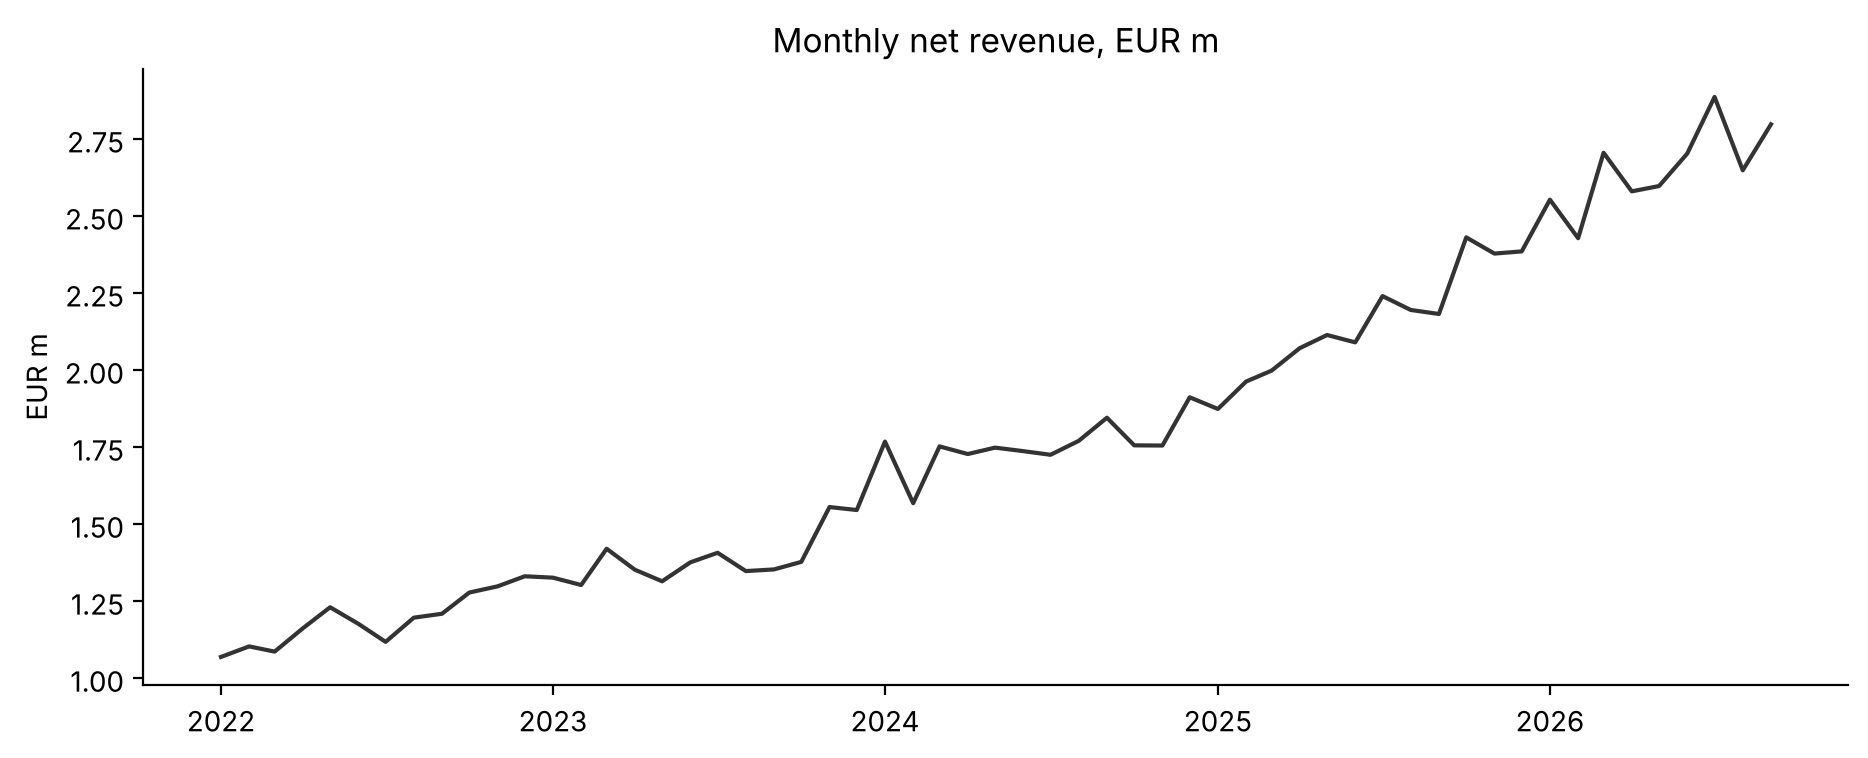

Net revenue growth vs same month last year, average by year:
month
2022     NaN
2023   0.173
2024   0.265
2025   0.231
2026   0.278
Name: net_revenue, dtype: float64


In [8]:
total = pnl.groupby("month")[["net_revenue", "arr"]].sum() / 1e6
growth = pnl.groupby("month")["net_revenue"].sum().pct_change(12)

fig, ax = plt.subplots()
ax.plot(total.index, total["net_revenue"], color="#333")
ax.set_title("Monthly net revenue, EUR m")
ax.set_ylabel("EUR m")
plt.show()

print("Net revenue growth vs same month last year, average by year:")
print(growth.groupby(growth.index.year).mean().round(3))

**Reading:** net revenue grows steadily, about a quarter per year. The line is smooth because most revenue is subscription: customers pay every month. The small spikes are months with many new customers, who pay a one-off onboarding fee.

## 3. Revenue mix: segment, stream and channel

The job call asks about business model mix. Here it has three sides: Mid-market vs Enterprise, subscription vs services, and direct vs partner sales.

In [9]:
by_seg = pnl.groupby(["year", "segment"])["net_revenue"].sum().unstack()
share_seg = by_seg.div(by_seg.sum(axis=1), axis=0)

streams = pnl.groupby("year")[["net_subscription", "services_revenue"]].sum()
share_stream = streams.div(streams.sum(axis=1), axis=0)

mix = pd.concat([share_seg, share_stream], axis=1)
mix.columns = ["Enterprise share", "Mid-market share", "Subscription share", "Services share"]
mix

,Enterprise share,Mid-market share,Subscription share,Services share
year,,,,
2022,0.495,0.505,0.918,0.082
2023,0.496,0.504,0.937,0.063
2024,0.526,0.474,0.921,0.079
2025,0.532,0.468,0.924,0.076
2026,0.576,0.424,0.927,0.073


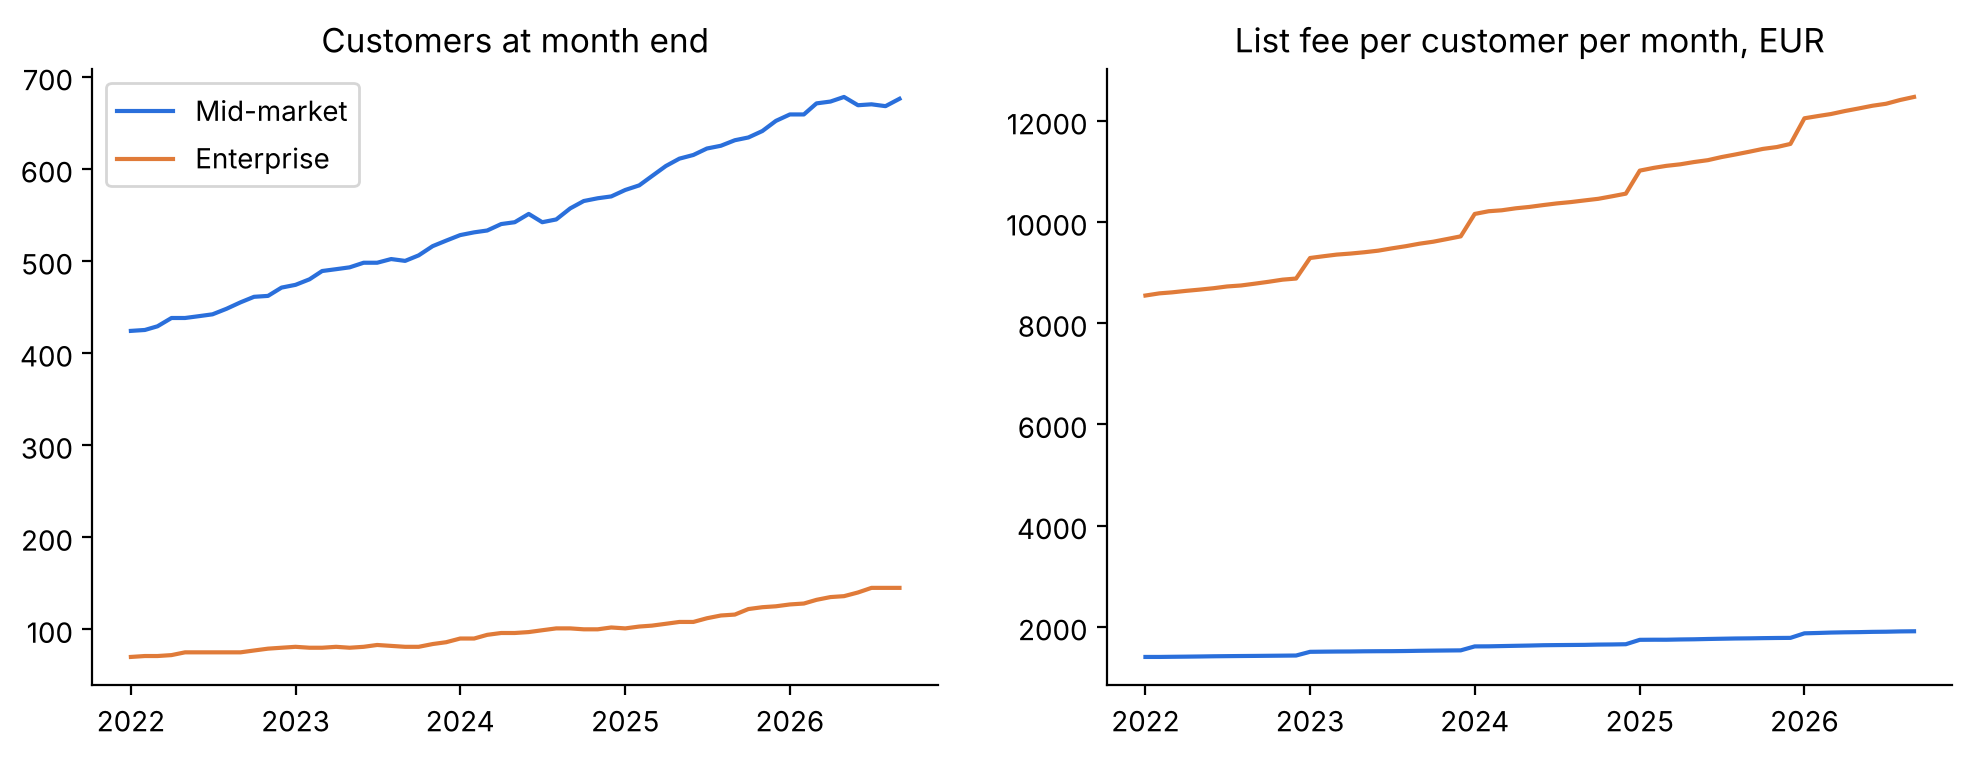

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for seg in ["Mid-market", "Enterprise"]:
    d = pnl[pnl["segment"] == seg]
    axes[0].plot(d["month"], d["closing_customers"], color=COLORS[seg], label=seg)
    axes[1].plot(d["month"], d["fee_per_customer"], color=COLORS[seg], label=seg)

axes[0].set_title("Customers at month end")
axes[1].set_title("List fee per customer per month, EUR")
axes[0].legend()
plt.show()

**Reading:** Mid-market has many small customers (about 420 at the start), Enterprise few large ones (about 70), paying about six times more each. Enterprise is a growing share of revenue. The fee per customer jumps every January (price increase) and rises slowly in between (upsell).

## 4. New customers: trend and seasonality

New customers are the driver with the most movement, and the one we will forecast with a time series model. B2B software is usually bought before the year end, when budgets must be spent, and less in summer.

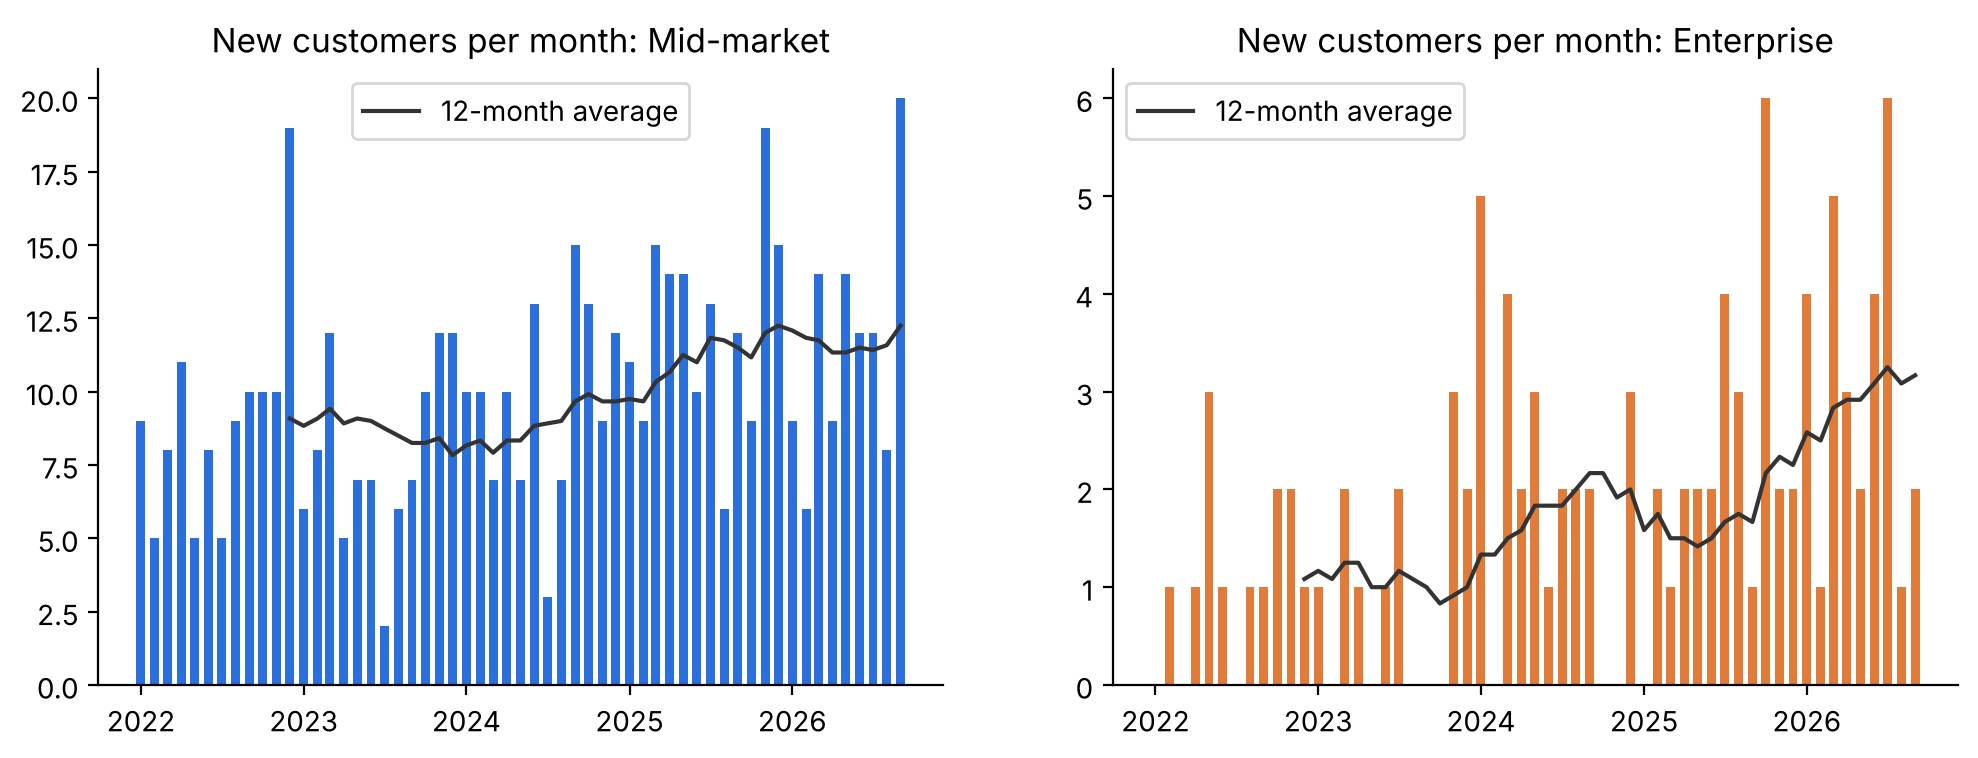

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, seg in enumerate(["Mid-market", "Enterprise"]):
    d = drivers[drivers["segment"] == seg].set_index("month")["new_customers"]
    axes[i].bar(d.index, d.values, width=20, color=COLORS[seg])
    axes[i].plot(d.rolling(12).mean(), color="#333", label="12-month average")
    axes[i].set_title(f"New customers per month: {seg}")
    axes[i].legend()
plt.show()

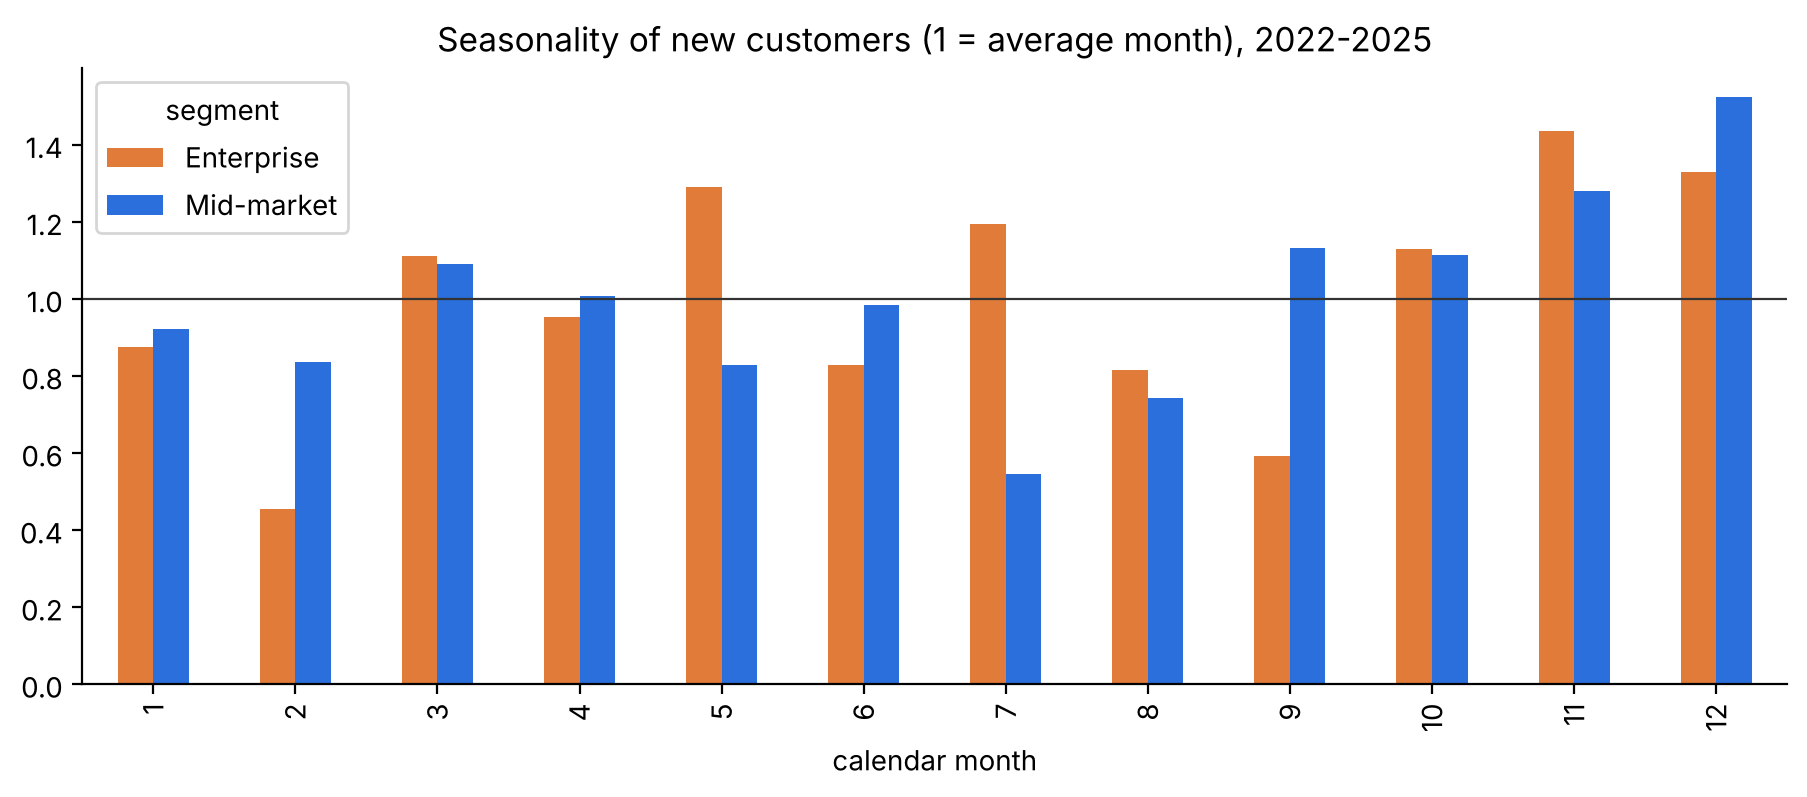

In [12]:
# Seasonality: each month's wins divided by that year's monthly average, then averaged over the years
d = drivers[drivers["month"] < "2026-01-01"].copy()   # full years only
d["year"] = d["month"].dt.year
d["calendar_month"] = d["month"].dt.month
d["index"] = d["new_customers"] / d.groupby(["segment", "year"])["new_customers"].transform("mean")

season = d.groupby(["calendar_month", "segment"])["index"].mean().unstack()
season.plot(kind="bar", color=[COLORS["Enterprise"], COLORS["Mid-market"]], figsize=(11, 4))
plt.axhline(1, color="#333", linewidth=0.8)
plt.title("Seasonality of new customers (1 = average month), 2022-2025")
plt.xlabel("calendar month")
plt.show()

**Reading:** for Mid-market, December is the strongest month (about 1.5 times an average month) and July and August the weakest. Enterprise wins only one or two deals a month, so its numbers jump around a lot and the pattern is noisy. This matters for the forecast: with so few deals, a monthly Enterprise forecast will always carry wide error, and a quarterly view is more honest.

This is also our **booking window**: when in the year customers sign decides how much revenue the year gets. A customer won in December adds one month of revenue to that year; one won in January adds twelve.

## 5. Churn (cancellations)

Churn rate = customers who cancelled in the month / customers at the start of the month.

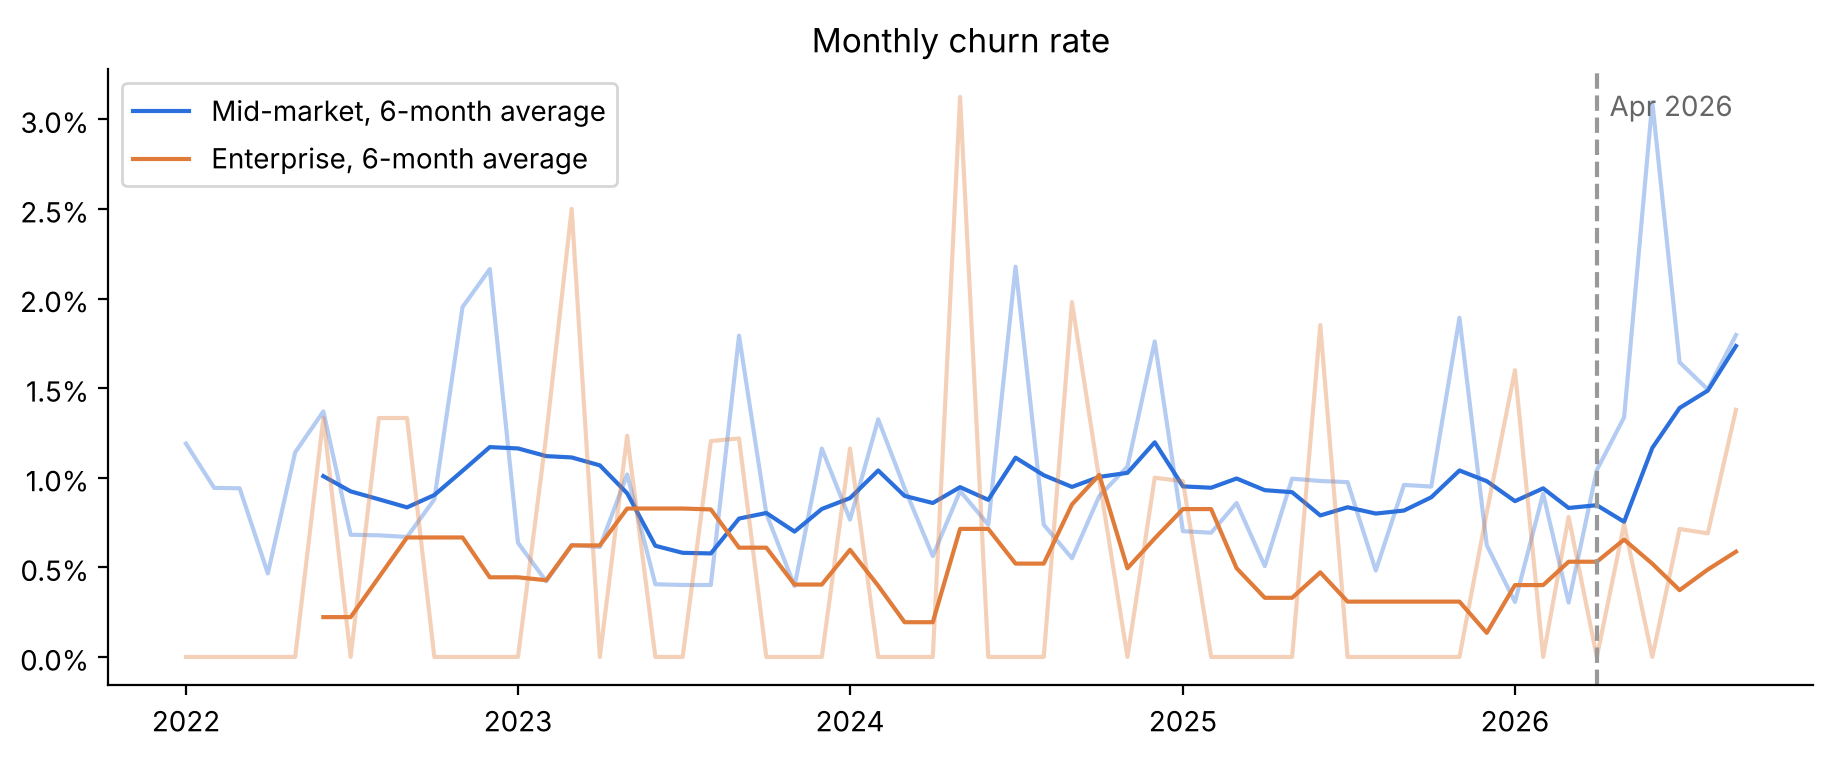

In [13]:
fig, ax = plt.subplots()
for seg in ["Mid-market", "Enterprise"]:
    d = drivers[drivers["segment"] == seg].set_index("month")["churn_rate"]
    ax.plot(d.index, d.values, color=COLORS[seg], alpha=0.35)
    ax.plot(d.rolling(6).mean(), color=COLORS[seg], label=f"{seg}, 6-month average")
ax.axvline(pd.Timestamp("2026-04-01"), color="#999", linestyle="--")
ax.text(pd.Timestamp("2026-04-15"), ax.get_ylim()[1] * 0.92, "Apr 2026", color="#666")
ax.set_title("Monthly churn rate")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.1%}")
ax.legend()
plt.show()

In [14]:
# Mid-market churn before and after April 2026
mm = drivers[drivers["segment"] == "Mid-market"]
before = mm[(mm["month"] >= "2025-04-01") & (mm["month"] < "2026-04-01")]["churn_rate"].mean()
after = mm[mm["month"] >= "2026-04-01"]["churn_rate"].mean()
print(f"Mid-market churn, Apr 2025-Mar 2026: {before:.2%} per month")
print(f"Mid-market churn, Apr 2026-Sep 2026: {after:.2%} per month")
print(f"In a year that is about {1 - (1 - before) ** 12:.0%} vs {1 - (1 - after) ** 12:.0%} of customers lost")

Mid-market churn, Apr 2025-Mar 2026: 0.82% per month
Mid-market churn, Apr 2026-Sep 2026: 1.74% per month
In a year that is about 9% vs 19% of customers lost


**Reading:** Mid-market churn was stable at about 0.8 to 1% a month until spring 2026, which means losing about 9% of customers a year. From April 2026 it jumps to about 1.7% a month, close to 19% a year. Enterprise churn jumps between 0% and 3% because one lost customer out of about 100 already moves the rate by 1 point, so its 6-month average is more useful than any single month. In the story behind the data, a competitor launched a cheaper product. The 2026 budget did not expect this, so it will be the biggest negative item in the outlook.

## 6. Leakage between list price and net revenue: discounts and partner commission

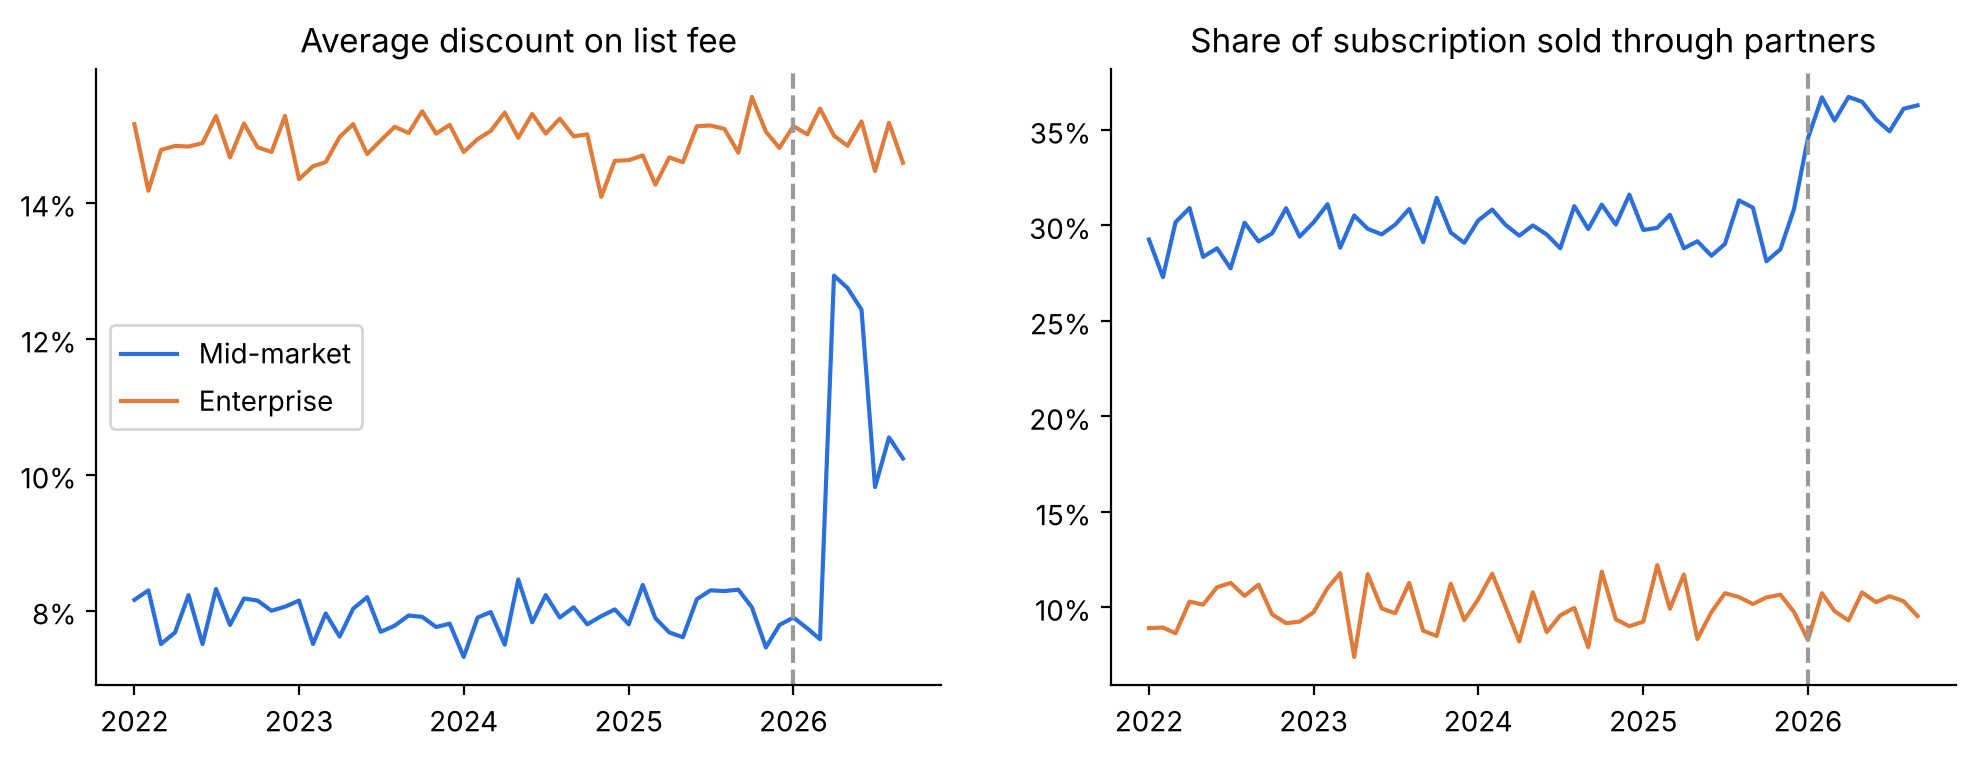

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for seg in ["Mid-market", "Enterprise"]:
    d = drivers[drivers["segment"] == seg]
    axes[0].plot(d["month"], d["discount_rate"], color=COLORS[seg], label=seg)
    axes[1].plot(d["month"], d["partner_share"], color=COLORS[seg], label=seg)
axes[0].set_title("Average discount on list fee")
axes[1].set_title("Share of subscription sold through partners")
for ax in axes:
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.axvline(pd.Timestamp("2026-01-01"), color="#999", linestyle="--")
axes[0].legend()
plt.show()

In [16]:
# How much of list revenue does not reach net revenue?
leak = pnl.groupby("year")[["gross_subscription", "discounts", "partner_commission"]].sum()
leak["discount_%"] = leak["discounts"] / leak["gross_subscription"]
leak["commission_%"] = leak["partner_commission"] / leak["gross_subscription"]
leak[["discount_%", "commission_%"]]

,discount_%,commission_%
year,,
2022,0.115,0.033
2023,0.114,0.034
2024,0.116,0.033
2025,0.117,0.032
2026,0.129,0.035


**Reading:** Enterprise gets larger discounts (about 15%) but sells mostly direct. Mid-market discounts were about 8% until 2026. In Q2 2026 a coupon campaign pushed the Mid-market discount to about 13%, and after the campaign it stayed higher (about 10%). More Mid-market deals also came through partners in 2026, which means more commission. Both reduce net revenue without changing the number of customers, so they are easy to miss if you only look at customer counts.

## 7. Gross margin

In [17]:
m = pnl.groupby(["year", "segment"])[["net_revenue", "gross_profit", "net_subscription",
                                      "subscription_gross_profit", "services_revenue",
                                      "services_gross_profit"]].sum()
m["gross_margin"] = m["gross_profit"] / m["net_revenue"]
m["subscription_margin"] = m["subscription_gross_profit"] / m["net_subscription"]
m["services_margin"] = m["services_gross_profit"] / m["services_revenue"]
m[["gross_margin", "subscription_margin", "services_margin"]].unstack()

gross_margin            subscription_margin             \
segment   Enterprise Mid-market          Enterprise Mid-market   
year                                                             
2022           0.784      0.746               0.818      0.790   
2023           0.799      0.766               0.828      0.800   
2024           0.796      0.774               0.838      0.809   
2025           0.808      0.780               0.848      0.818   
2026           0.814      0.788               0.854      0.820   

        services_margin             
segment      Enterprise Mid-market  
year                                
2022              0.352      0.301  
2023              0.330      0.297  
2024              0.359      0.303  
2025              0.344      0.296  
2026              0.358      0.302

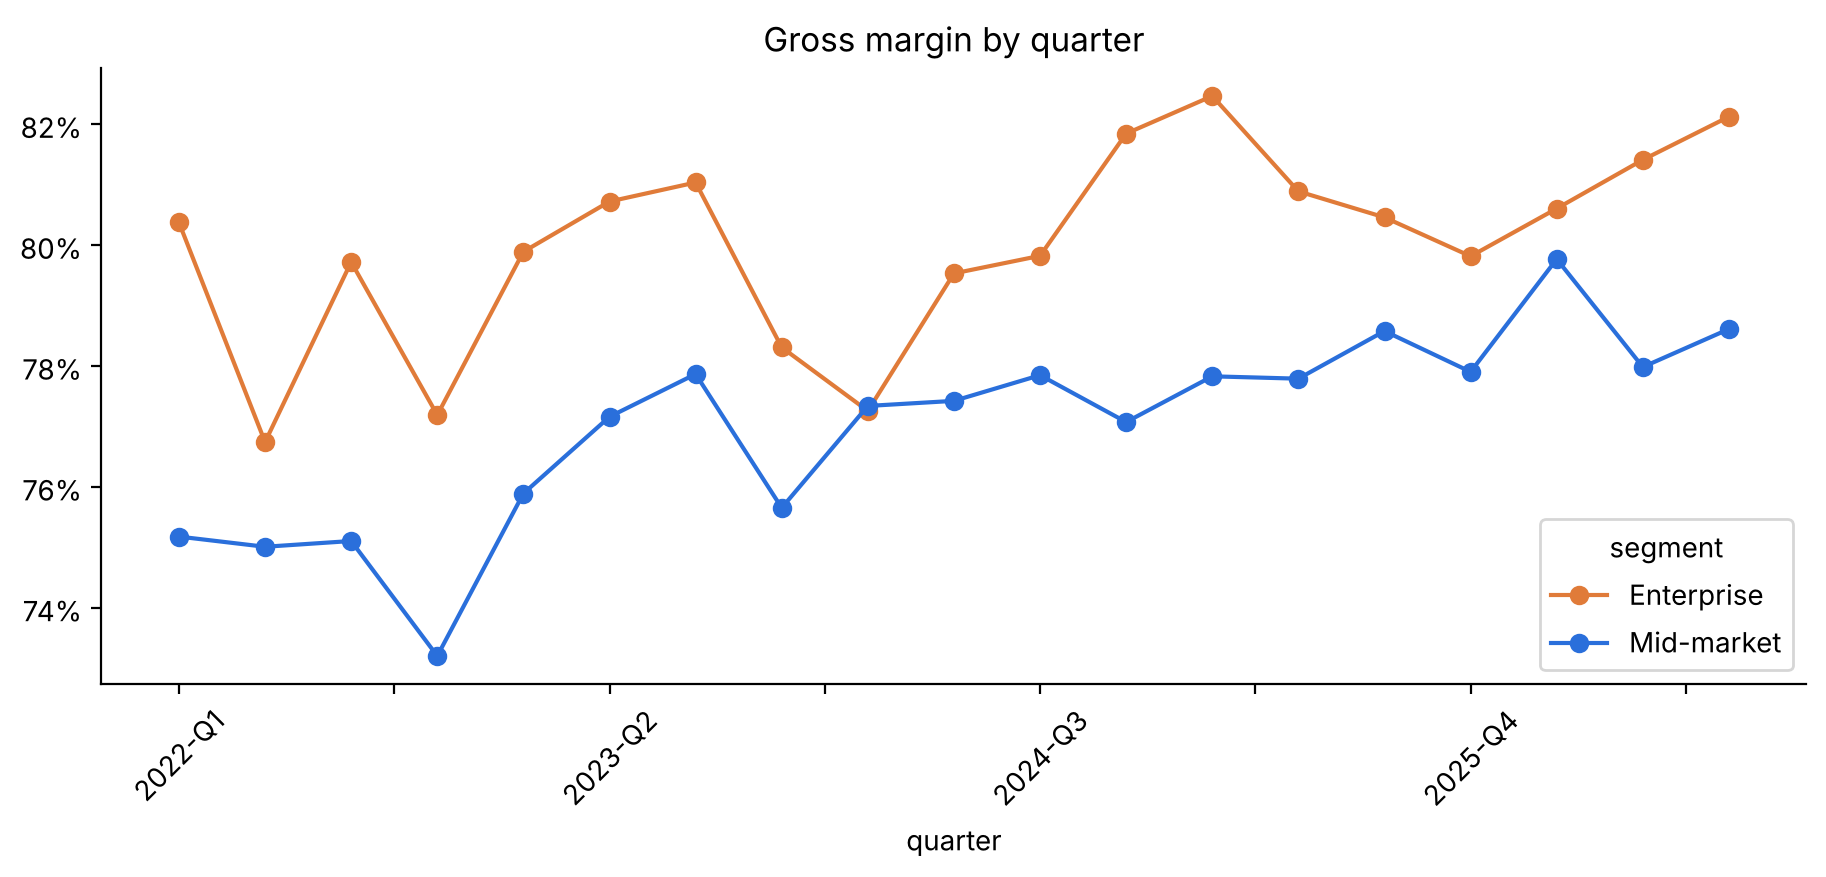

In [18]:
q = pnl.groupby(["quarter", "segment"])[["gross_profit", "net_revenue"]].sum()
q["gross_margin"] = q["gross_profit"] / q["net_revenue"]
q = q["gross_margin"].unstack()

ax = q.plot(color=[COLORS["Enterprise"], COLORS["Mid-market"]], marker="o")
ax.set_title("Gross margin by quarter")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.xticks(rotation=45)
plt.show()

**Reading:** subscription earns a margin of about 80 to 85%: once the software is built, serving one more customer costs little (hosting, support). Onboarding services earn about 30 to 35%, because consultants are paid for each project. So the more revenue comes from services, the lower the total margin. Margins rise a little every year because the January price increase is larger than the growth in cost per customer. In 2026 the higher discounts and commission do not show as a lower margin %; they show as lower revenue than planned, which we will see when we compare with the budget.

## 8. What this means for the forecast

| Driver | What the data shows | How to forecast it |
|---|---|---|
| New customers | Growing trend + strong seasonality (December high, summer low); Enterprise very noisy | Time series with trend and seasonality (Holt-Winters), per segment |
| Churn | Stable, then a jump in Mid-market from April 2026 | Recent average (last 6 months), not the long-run average |
| Price increase | Once a year in January | Planned number, not forecast |
| Expansion | Small and stable | Long-run average |
| Discount | Stable, then a Q2 2026 campaign and a higher level after it | Last 3 months |
| Partner share | Higher in Mid-market in 2026 | Last 3 months |
| Unit costs | Stable; support cost grows with wages | Average + inflation |

The three 2026 events (Mid-market churn, coupon campaign, more partner sales) are what the Q3 outlook has to explain against the budget. The strong Enterprise wins in Q3 2026 partly offset them.

Next step: build the 2026 budget from 2025 drivers, then compare the actuals with it.